# Логистическая регрессия: прогнозирование оттока клиентов банка

### 1. Первичный анализ данных (EDA)

#### Задание 1.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression as lr

In [2]:
df = pd.read_csv("Churn_Modelling.csv", sep=",", encoding="utf_8")
df.info()
df.head(20)

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   CreditScore      10000 non-null  int64  
 3   Gender           10000 non-null  str    
 4   Age              10000 non-null  int64  
 5   Tenure           10000 non-null  int64  
 6   Balance          10000 non-null  float64
 7   NumOfProducts    10000 non-null  int64  
 8   HasCrCard        10000 non-null  int64  
 9   IsActiveMember   10000 non-null  int64  
 10  EstimatedSalary  10000 non-null  float64
 11  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(1)
memory usage: 937.6 KB


,RowNumber,CustomerId,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,619,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,608,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,502,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,699,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,850,Female,43,2,125510.82,1,1,1,79084.10,0
5,6,15574012,645,Male,44,8,113755.78,2,1,0,149756.71,1
6,7,15592531,822,Male,50,7,0.00,2,1,1,10062.80,0
7,8,15656148,376,Female,29,4,115046.74,4,1,0,119346.88,1
8,9,15792365,501,Male,44,4,142051.07,2,0,1,74940.50,0
9,10,15592389,684,Male,27,2,134603.88,1,1,1,71725.73,0


In [3]:
df.tail(n=10)

,RowNumber,CustomerId,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9990,9991,15798964,714,Male,33,3,35016.60,1,1,0,53667.08,0
9991,9992,15769959,597,Female,53,4,88381.21,1,1,0,69384.71,1
9992,9993,15657105,726,Male,36,2,0.00,1,1,0,195192.40,0
9993,9994,15569266,644,Male,28,7,155060.41,1,1,0,29179.52,0
9994,9995,15719294,800,Female,29,2,0.00,2,0,0,167773.55,0
9995,9996,15606229,771,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,516,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,709,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,772,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,792,Female,28,4,130142.79,1,1,0,38190.78,0


In [4]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [5]:
print(f"Строк: {len(df)}")
print(f"Пропуски:\n{df.isna().sum()}")

Строк: 10000
Пропуски:
RowNumber          0
CustomerId         0
CreditScore        0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


Пропусков нет, аномалий не выявлено. В описательной статистике видно, что есть умеренный дисбаланс, около 20% клиентов ушли.

#### Задание 2.

Text(0.5, 1.0, 'Распредение переменой Exited')

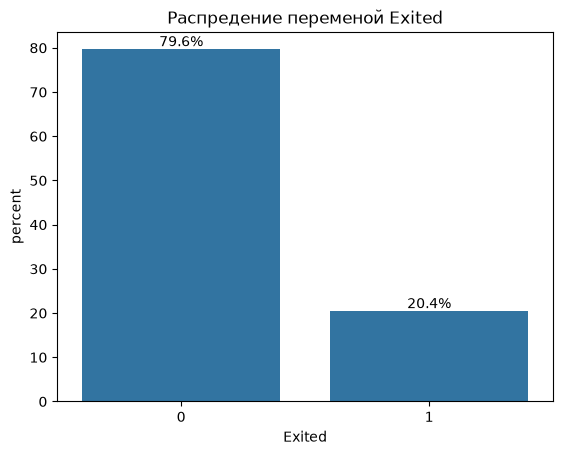

In [6]:
ax = sns.countplot(df, x="Exited", stat="percent")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="edge", padding=0)
plt.title("Распредение переменой Exited")

Редкий класс встречается в 20.4%, что с учетом выборки в 10000 объектов, является умеренным дисбалансом.

#### Задание 3.

In [7]:
df.drop(["Gender"], axis=1).corr(method="pearson")

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,1.000000,0.004202,0.005840,0.000783,-0.006495,-0.009067,0.007246,0.000599,0.012044,-0.005988,-0.016571
CustomerId,0.004202,1.000000,0.005308,0.009497,-0.014883,-0.012419,0.016972,-0.014025,0.001665,0.015271,-0.006248
CreditScore,0.005840,0.005308,1.000000,-0.003965,0.000842,0.006268,0.012238,-0.005458,0.025651,-0.001384,-0.027094
Age,0.000783,0.009497,-0.003965,1.000000,-0.009997,0.028308,-0.030680,-0.011721,0.085472,-0.007201,0.285323
Tenure,-0.006495,-0.014883,0.000842,-0.009997,1.000000,-0.012254,0.013444,0.022583,-0.028362,0.007784,-0.014001
Balance,-0.009067,-0.012419,0.006268,0.028308,-0.012254,1.000000,-0.304180,-0.014858,-0.010084,0.012797,0.118533
NumOfProducts,0.007246,0.016972,0.012238,-0.030680,0.013444,-0.304180,1.000000,0.003183,0.009612,0.014204,-0.047820
HasCrCard,0.000599,-0.014025,-0.005458,-0.011721,0.022583,-0.014858,0.003183,1.000000,-0.011866,-0.009933,-0.007138
IsActiveMember,0.012044,0.001665,0.025651,0.085472,-0.028362,-0.010084,0.009612,-0.011866,1.000000,-0.011421,-0.156128
EstimatedSalary,-0.005988,0.015271,-0.001384,-0.007201,0.007784,0.012797,0.014204,-0.009933,-0.011421,1.000000,0.012097


<Axes: >

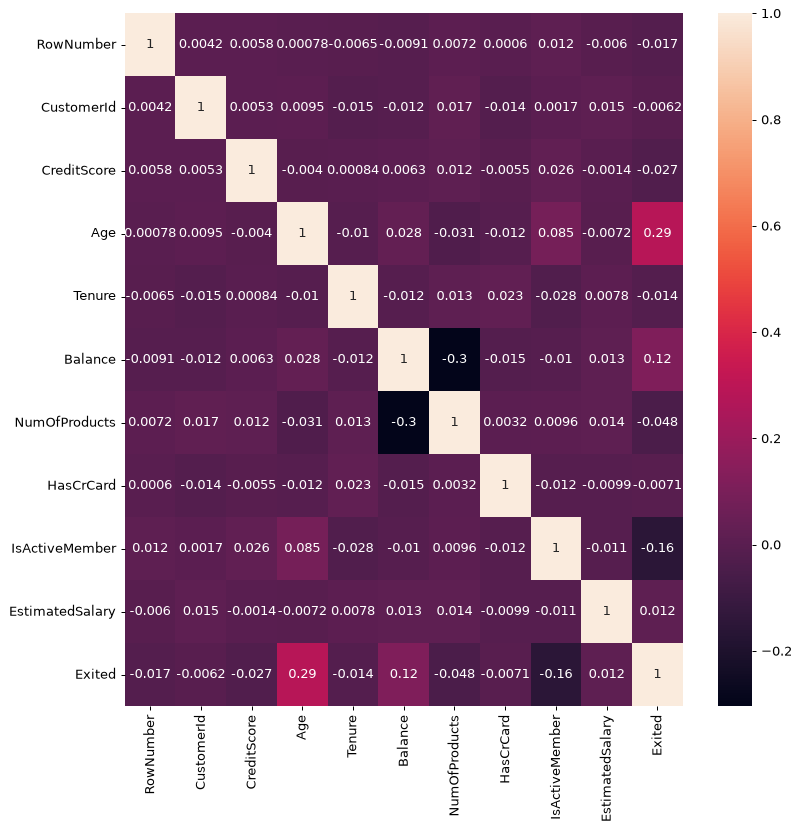

In [8]:
plt.figure(figsize=(10, 10), dpi=90)
sns.heatmap(
    df.drop(["Gender"], axis=1).corr(),
    xticklabels=df.drop(["Gender"], axis=1).corr().columns,
    yticklabels=df.drop(["Gender"], axis=1).corr().columns,
    annot=True,
)

С Exited сильнее всего коррелирует возраст, балланс и активность.

#### Задание 4.

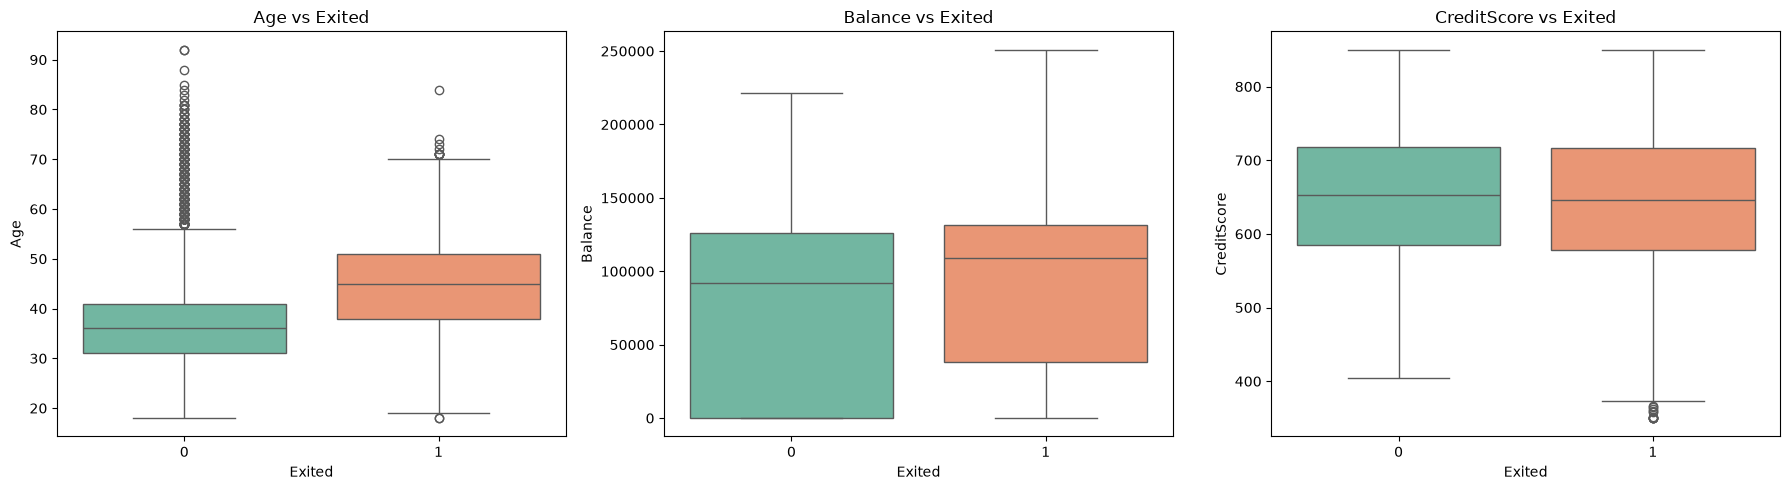

In [9]:
features = ["Age", "Balance", "CreditScore"]
fig, axes = plt.subplots(1, len(features), figsize=(18, 5))

for ax, col in zip(axes, features):
    sns.boxplot(
        data=df, x="Exited", y=col, palette="Set2", ax=ax, hue="Exited", legend=False
    )
    ax.set_title(f"{col} vs Exited")
    ax.set_xlabel("Exited")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

У ушедших клиентов медиана примерно на 10 "лет" выше. Клиенты страшего возраста уходят чаще.
У ушедших клиентов баланс больше. А кредитный рейтинг почти не влияет на отток клиентов.

### 2. Предобработка данных

#### Задание 5.

In [10]:
df["Gender"] = df["Gender"].map({"Male": 1, "Female": 0})

#### Задание 6.

In [11]:
y = df["Exited"]
X = df.drop(["Exited"], axis=1)
X = StandardScaler().fit_transform(X)

X = pd.DataFrame(
    X,
    columns=df.columns.drop("Exited"),
    index=df.index,
)

X.head()

,RowNumber,CustomerId,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,-1.731878,-0.783213,-0.326221,-1.095988,0.293517,-1.041760,-1.225848,-0.911583,0.646092,0.970243,0.021886
1,-1.731531,-0.606534,-0.440036,-1.095988,0.198164,-1.387538,0.117350,-0.911583,-1.547768,0.970243,0.216534
2,-1.731185,-0.995885,-1.536794,-1.095988,0.293517,1.032908,1.333053,2.527057,0.646092,-1.030670,0.240687
3,-1.730838,0.144767,0.501521,-1.095988,0.007457,-1.387538,-1.225848,0.807737,-1.547768,-1.030670,-0.108918
4,-1.730492,0.652659,2.063884,-1.095988,0.388871,-1.041760,0.785728,-0.911583,0.646092,0.970243,-0.365276


#### Задание 7.

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [15]:
print(y_train.value_counts(normalize=True).round(4) * 100)
print(y_test.value_counts(normalize=True).round(4) * 100)

Exited
0    79.6
1    20.4
Name: proportion, dtype: float64
Exited
0    79.75
1    20.25
Name: proportion, dtype: float64


Баланс классов сохранился